In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset'] = 'cm'
import pandas as pd
import openflash as of
import gmsh, pygmsh
print(type(of))
print(of.__path__)
print(of.__file__)

import time
import capytaine as cpt
from capytaine.io.meshio import load_from_meshio
import sys
import os
import xarray as xr
# Define the path to the directory containing the package
utils_path = r"C:\Users\15183\OpenFLASH\sea-lab-utils"

if utils_path not in sys.path:
    sys.path.append(utils_path)



<class 'module'>
['C:\\Users\\15183\\OpenFLASH\\package\\src\\openflash']
C:\Users\15183\OpenFLASH\package\src\openflash\__init__.py


In [2]:
omegas = np.linspace(0.1, 2.5, 25)
h = 100
rho = of.rho
g = of.g

# a_list = [[1.5], [3.5, 5.5]] 
# d_list = [[5], [3, 1]]
a_list = [[3], [10]] 
d_list = [[40], [2]]
betas = np.array([0.0])
heaving = [True, True]
truncation_order = 500

num_regions = sum([len(a_vals) for a_vals in a_list])
NMK = [truncation_order] * (num_regions+1)

In [3]:
# OpenFLASH

bodies_sweep = []
for a_vals, d_vals, heave_val in zip(a_list, d_list, heaving):
    body = of.SteppedBody(
        a=np.array(a_vals),
        d=np.array(d_vals),
        slant_angle= np.zeros_like(a_vals),
        heaving=heave_val
    )
    bodies_sweep.append(body)

# Create arrangement
arrangement_sweep = of.ConcentricBodyGroup(bodies_sweep)

# Create geometry
geometry_sweep = of.BasicRegionGeometry(
    body_arrangement=arrangement_sweep,
    h=h,
    NMK=NMK
)

# Create the MEEMProblem instance
problem = of.MEEMProblem(geometry_sweep)

# Set the frequencies for the sweep
problem.set_frequencies(omegas)

# Initialize a new MEEM Engine for this problem
engine = of.MEEMEngine(problem_list=[problem])

# Solve
results = engine.run_and_store_results(0)
OpenFLASH_results = results.get_results()

# Reorganize to match Capytaine 
added_mass_data = OpenFLASH_results.added_mass.values
radiation_damping_data = OpenFLASH_results.damping.values
excitation_force_mag_data = OpenFLASH_results.excitation_force.values
excitation_force_phase_data = OpenFLASH_results.excitation_phase.values
excitation_force_data = excitation_force_mag_data[:,None] * np.exp(1j * excitation_force_phase_data[:,None])

wavenumbers = np.array([of.wavenumber(omega,h) for omega in omegas])


dof_list = []
for i, heave in enumerate(heaving):
    if heave:
        dof_list.append(f'fb{i}__Heave')
num_dofs = len(dof_list)

influenced_dof_cat = pd.Categorical(dof_list)
radiating_dof_cat = pd.Categorical(dof_list)

# Dummy data
added_mass_data = added_mass_data.reshape(len(omegas),num_dofs,num_dofs)
radiation_damping_data = radiation_damping_data.reshape(len(omegas),num_dofs,num_dofs)
excitation_force_data = excitation_force_data.reshape(len(omegas),1,num_dofs)

# Create the Dataset
of_data = xr.Dataset(
    data_vars={
        "added_mass": (["omega", "radiating_dof", "influenced_dof"], added_mass_data),
        "radiation_damping": (["omega", "radiating_dof", "influenced_dof"], radiation_damping_data),
        "excitation_force": (["omega", "wave_direction", "influenced_dof"], excitation_force_data)            
    },
    coords={
        "g":g,
        "rho":rho,
        "body_name":"body",
        "water_depth":h,
        "forward_speed":0.0,
        "wave_direction": np.array([0.0]),
        "omega": omegas,
        "radiating_dof": radiating_dof_cat,
        "influenced_dof": influenced_dof_cat,
        "period": ("omega", (2*np.pi)/omegas), # seconds
        "wavenumber": ("omega", wavenumbers), # rad/m
        "wavelength": ("omega", (2*np.pi)/wavenumbers)                
    }
)
of_data


Hydrodynamic coefficients stored in xarray dataset.
Potentials stored in xarray dataset (batched across frequencies/modes).


<xarray.Dataset> Size: 3kB
Dimensions:            (omega: 25, radiating_dof: 2, influenced_dof: 2,
                        wave_direction: 1)
Coordinates:
  * omega              (omega) float64 200B 0.1 0.2 0.3 0.4 ... 2.2 2.3 2.4 2.5
  * radiating_dof      (radiating_dof) category 18B fb0__Heave fb1__Heave
  * influenced_dof     (influenced_dof) category 18B fb0__Heave fb1__Heave
  * wave_direction     (wave_direction) float64 8B 0.0
    g                  float64 8B 9.81
    rho                int64 8B 1023
    body_name          <U4 16B 'body'
    water_depth        int64 8B 100
    forward_speed      float64 8B 0.0
    period             (omega) float64 200B 62.83 31.42 20.94 ... 2.618 2.513
    wavenumber         (omega) float64 200B 0.003248 0.006853 ... 0.5872 0.6371
    wavelength         (omega) float64 200B 1.934e+03 916.8 555.6 ... 10.7 9.862
Data variables:
    added_mass         (omega, radiating_dof, influenced_dof) float64 800B 5....
    radiation_damping  (omega, radiating_dof, influenced_dof) float64 800B 20...
    excitation_force   (omega, wave_direction, influenced_dof) complex128 800B ...

In [4]:
# BEM
mesh_size_factor = 0.2
mesh_list = []
lid_mesh_list = []
fb_list = []
v_shift = 1e-4

for i, heave in enumerate(heaving):
    a_vals = a_list[i]
    d_vals = d_list[i]

    with pygmsh.occ.Geometry() as geom:
        gmsh.option.setNumber('Mesh.MeshSizeFactor', mesh_size_factor)

        if len(a_vals) == 1:
            cyls = geom.add_cylinder([0, 0, v_shift], [0, 0, -d_vals[0]], a_vals[0])
        else:
            cyls = None
            for a, d in zip(a_vals, d_vals):
                cyl = geom.add_cylinder([0, 0, v_shift], [0, 0, -d], a)
                if cyls is None:
                    cyls = cyl
                else:
                    # Pass entities as a list [cyls, cyl]
                    cyls = geom.boolean_union([cyls, cyl], delete_first=True, delete_other=True)

        # Determine cut-out for previous body
        if i > 0:
            # Slightly extend z-bounds (+1e-3, -2e-3) to avoid coincident boundary surface failures
            max_d = max(d_vals)
            r_cut = a_list[i-1][-1]
            hollow = geom.add_cylinder([0, 0, v_shift + 1e-3], [0, 0, -(max_d + 2e-3)], r_cut)
            
            # Pass input and tool as a list [cyls, hollow]
            cyls = geom.boolean_difference(cyls, hollow, delete_first=True, delete_other=True)

        mesh = geom.generate_mesh()

    # Convert Mesh & Instantiate FloatingBody
    mesh_name = f"mesh{i}"
    mesh_obj = load_from_meshio(mesh, mesh_name)
    lid_mesh_obj = mesh_obj.generate_lid(z=-1e-2)
    mesh_list.append(mesh_obj)
    lid_mesh_list.append(lid_mesh_obj)

    fb_name = f"fb{i}"
    fb = cpt.FloatingBody(mesh=mesh_obj, lid_mesh=lid_mesh_obj, name=fb_name).keep_immersed_part()
    if heave:
        fb.add_translation_dof(name='Heave')
    fb_list.append(fb)

9.862087658149079
Body 0 with 2824 panels


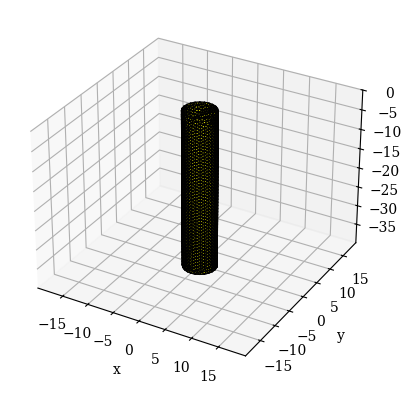

Max panel radius sufficiently small
Body 1 with 3357 panels


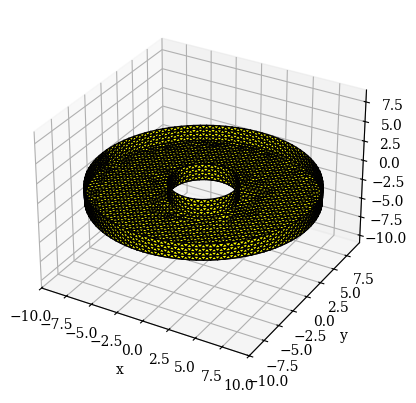

Max panel radius sufficiently small


In [8]:
smallest_wavelength = 2*np.pi/of.wavenumber(np.max(omegas),h)
print(smallest_wavelength)
for i, fb in enumerate(fb_list):
    print(f"Body {i} with {fb.mesh.nb_faces} panels")
    fb.show_matplotlib()

    # Check mesh size
    largest_panel_rad = np.max(fb.mesh.faces_radiuses)
    if largest_panel_rad<smallest_wavelength/8:
        print("Max panel radius sufficiently small")
    else:
        print(f"Max panel radius too large since {np.round(largest_panel_rad,2)} is not < {np.round(smallest_wavelength/8,2)}")

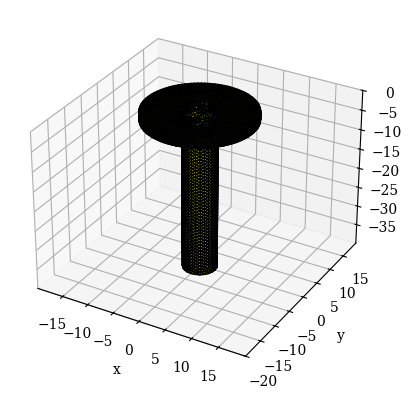

Output()

DOFs: ['fb0__Heave', 'fb1__Heave']


In [6]:
combinedfb = cpt.FloatingBody.join_bodies(*fb_list)
combinedfb.show_matplotlib()
combined_dofs_keys = list(combinedfb.dofs.keys())
print(f"DOFs: {combined_dofs_keys}")
input_dict = {"omega":omegas,
            "wave_direction":betas,
            "radiating_dof":combined_dofs_keys,
            "water_depth":h,
            "rho":rho,
            "g":g}
test_matrix = xr.Dataset(coords=input_dict)
cpt_data = cpt.BEMSolver().fill_dataset(test_matrix, combinedfb)

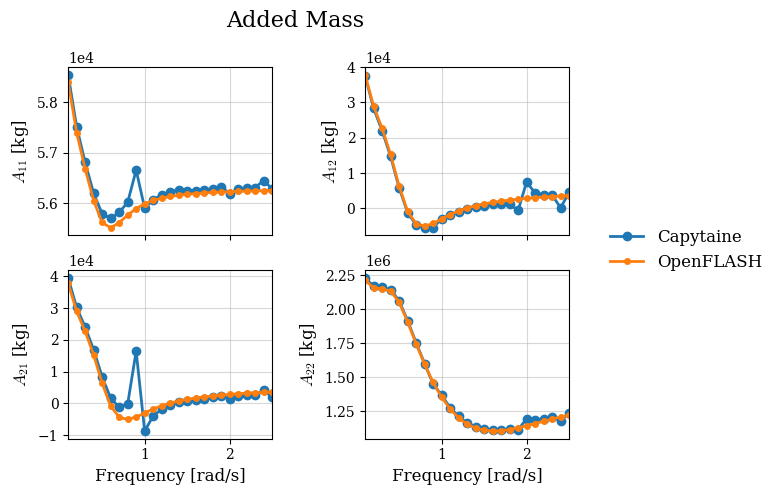

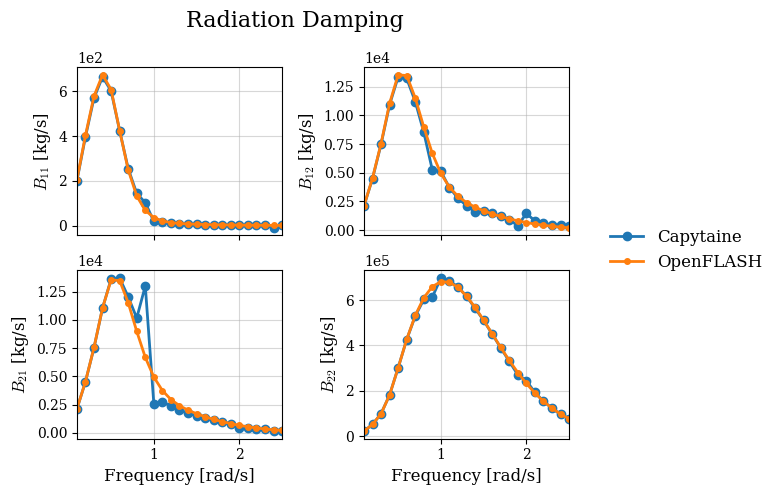

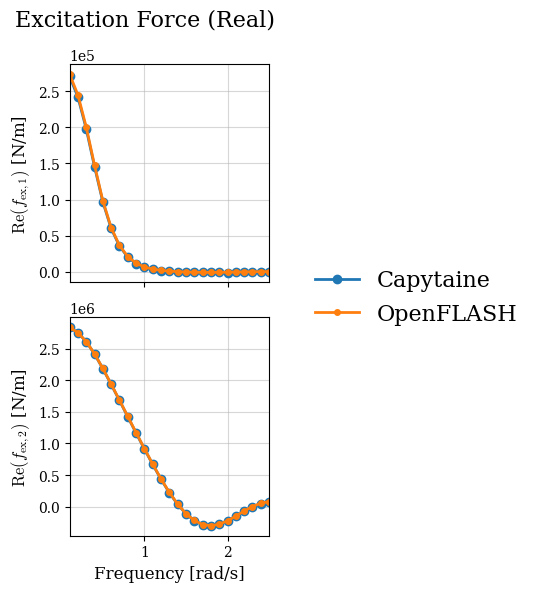

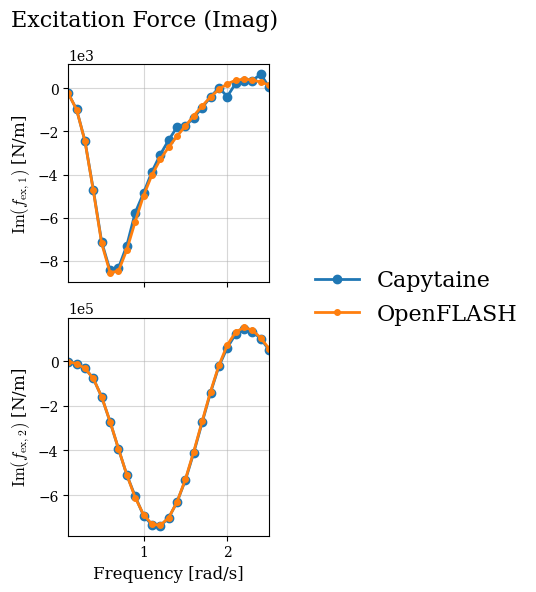

In [10]:
N_dofs = len(combined_dofs_keys)
N_omega = len(omegas)
N_beta = len(betas)

font_size = 12
marker_dict = {"Capytaine":'o',
           "OpenFLASH":'o'}
marker_size_dict = {"Capytaine":6,
           "OpenFLASH":4}

# Added Mass and Radiation Damping
all_added_mass = {"Capytaine":cpt_data.added_mass,
                 "OpenFLASH":of_data.added_mass}
all_radiation_damping = {"Capytaine":cpt_data.radiation_damping,
                 "OpenFLASH":of_data.radiation_damping}

all_rad_data = {"Added Mass":all_added_mass,
                 "Radiation Damping":all_radiation_damping}

for data_name, r_data in all_rad_data.items():
    fig, ax = plt.subplots(N_dofs,N_dofs, figsize=(3*N_dofs,2.5*N_dofs), sharex=True, squeeze=False)
    for method_name, rad_data in r_data.items():        
        for i_inf, inf_dof in enumerate(combined_dofs_keys):
            for i_rad, rad_dof in enumerate(combined_dofs_keys):
                ax[i_inf,i_rad].plot(omegas,
                                    rad_data.sel(influenced_dof=inf_dof,
                                                radiating_dof=rad_dof).values.flatten(),
                                                marker=marker_dict[method_name],
                                                    markersize=marker_size_dict[method_name],
                                                    linewidth=2,
                                                    label=method_name)
                ax[i_inf, i_rad].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
                
                if i_inf==N_dofs-1:
                    ax[i_inf,i_rad].set_xlabel('Frequency [rad/s]', fontsize=font_size)
                if data_name=="Added Mass":
                    ylab = f"$A_{{{i_inf+1}{i_rad+1}}}$ [kg]"
                elif data_name=="Radiation Damping":
                    ylab = f"$B_{{{i_inf+1}{i_rad+1}}}$ [kg/s]"
                ax[i_inf,i_rad].set_ylabel(ylab, fontsize=font_size)
                ax[i_inf,i_rad].set_xlim([np.min(omegas), np.max(omegas)])
                ax[i_inf,i_rad].grid(True, alpha=0.5)
                ax[i_inf,i_rad].set_axisbelow(True)
    fig.suptitle(data_name, fontsize=font_size + 4)
    plt.tight_layout()

    # Pull labels from one subplot and place legend outside the right edge
    handles, labels = ax[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize=font_size, frameon=False)

    save_name = f"{data_name}.pdf"
    fig.savefig(
        save_name, format="pdf", dpi=300, bbox_inches="tight"
    )

# Excitation force
all_r_ex = {"Capytaine":np.real(cpt_data.excitation_force),
                "OpenFLASH":np.real(of_data.excitation_force)}

all_i_ex = {"Capytaine":np.imag(cpt_data.excitation_force),
                "OpenFLASH":np.imag(of_data.excitation_force)}

all_ex_data = {"Excitation Force (Real)":all_r_ex,
                "Excitation Force (Imag)":all_i_ex}

for data_name, e_data in all_ex_data.items():
    fig, ax = plt.subplots(N_dofs,N_beta, figsize=(3*N_beta,3*N_dofs), sharex=True, squeeze=False)
    for method_name, ex_data in e_data.items():       
        for i_inf, inf_dof in enumerate(combined_dofs_keys):
            for i_beta, beta in enumerate(betas):
                ax[i_inf,i_beta].plot(omegas,
                                        ex_data.sel(influenced_dof=inf_dof,
                                                    wave_direction=beta).values.flatten(),
                                                    marker=marker_dict[method_name],
                                                    markersize=marker_size_dict[method_name],
                                                        linewidth=2,
                                                        label=method_name)
                ax[i_inf, i_beta].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
                
                if i_inf==N_dofs-1:
                    ax[i_inf,i_beta].set_xlabel('Frequency [rad/s]', fontsize=font_size)
                if data_name == "Excitation Force (Real)":
                    ylab = f"$\\mathrm{{Re}}(f_{{\\mathrm{{ex}},{i_inf+1}}})$ [N/m]"
                elif data_name == "Excitation Force (Imag)":
                    ylab = f"$\\mathrm{{Im}}(f_{{\\mathrm{{ex}},{i_inf+1}}})$ [N/m]"
                ax[i_inf,i_beta].set_ylabel(ylab, fontsize=font_size)
                ax[i_inf,i_beta].set_xlim([np.min(omegas), np.max(omegas)])
                ax[i_inf,i_beta].grid(True, alpha=0.5)
                ax[i_inf,i_beta].set_axisbelow(True)
                wave_dir_lab = f"$\\beta={beta}$"
                # ax[i_inf,i_beta].set_title(wave_dir_lab, font_size)
    fig.suptitle(data_name, fontsize=font_size + 4)
    plt.tight_layout()

    # Pull labels from one subplot and place legend outside the right edge
    handles, labels = ax[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize=font_size+4, frameon=False)

    save_name = f"{data_name}.pdf"
    fig.savefig(
        save_name, format="pdf", dpi=300, bbox_inches="tight"
    )



